# TP Chaînes de Markov - Master M2 IMB

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.random import choice as choice

## Exercice 1

### Question 1

In [16]:
# On fait d'abord quelques essais "au brouillon", pour préparer la réponse à la question:

# On crée un vecteur de taille n=10 qui contiendra les valeurs de x1, x2, ... simulées.
n = 10
x = np.zeros(n, dtype=int)
print(x)

[0 0 0 0 0 0 0 0 0 0]


In [17]:
# On initialise x[0]=1 (= valeur de x1):
x[0] = 1
# puis on simule x[1] (= valeur de x2), en tirant au sort suivant la loi conditionnelle P(X2=1|X1=1)=0.37, P(X2=2|X1=1)=0.63:
x[1] = choice([1,2],p=[0.37,0.63])
print(x[1])

1


In [18]:
# puis on simule x[2] (= valeur de x3), en tirant au sort suivant la loi conditionnelle, 
# qui dépend de la valeur de x[1]:
if x[1]==1:
    x[2] = choice([1,2],p=[0.37,0.63])
else:
    x[2] = choice([1,2],p=[0.42,0.58])
print(x[2])

1


In [20]:
# A présent on peut répondre à la question: on définit une fonction qui renvoie le vecteur x contenant les valeurs
# simulées de la chaîne de Markov (N.B on n'est pas obligé d'écrire une fonction, on pourrati aussi écrire le code directement):

def simul_markov(n,x1):
    x = np.zeros(n, dtype=int)
    x[0] = x1
    for i in range(n-1):
        if x[i]==1:
            x[i+1] = choice([1,2],p=[0.37,0.63])
        else:
            x[i+1] = choice([1,2],p=[0.42,0.58])
    return x

# On teste la fonction:
x = simul_markov(10,1)
print(x)

[1 2 2 1 1 2 1 2 1 2]


In [23]:
# Si on teste plusieurs fois, on obtient des simulations différentes:
x=simul_markov(10,1); print(x)
x=simul_markov(10,1); print(x)
x=simul_markov(10,1); print(x)
x=simul_markov(10,1); print(x)

[1 1 2 1 1 1 2 2 2 2]
[1 1 1 2 2 1 2 1 1 2]
[1 2 1 2 1 1 2 2 2 1]
[1 2 1 1 1 2 2 1 2 2]


In [25]:
# Test en partant de l'état 2 au lieu de l'état 1:
x=simul_markov(10,2)
print(x)

[2 2 1 2 1 1 1 2 2 2]


In [26]:
# Test pour n=100
x=simul_markov(100,1)
print(x)

[1 1 2 2 2 1 2 2 1 2 2 1 2 2 1 2 2 1 2 1 2 2 2 1 1 2 1 1 2 1 2 2 1 2 2 2 2
 2 1 2 1 2 2 1 2 1 1 1 2 1 2 1 2 2 2 2 1 1 1 1 1 1 2 2 1 1 2 1 1 2 1 2 2 1
 2 1 2 1 1 1 2 1 1 1 2 1 2 2 2 1 2 1 1 2 1 1 1 2 1 2]


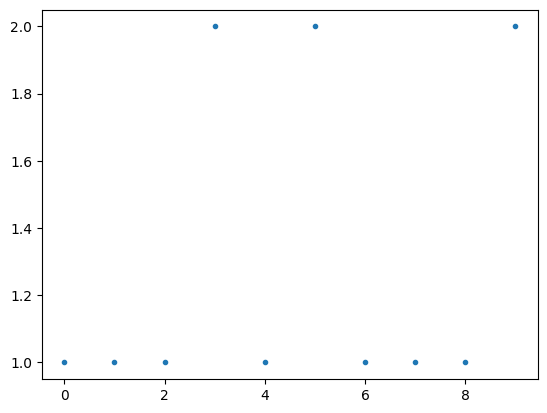

In [27]:
# affichage graphique:
x = simul_markov(10,1)
plt.plot(x,'.');

### Question 3

In [29]:
# On pourrait recopier le code de la question 1 en modifiant les valeurs des probabilités,
# mais on va en profiter pour faire une fonction plus générique qui prend en entrée la 
# matrice de transition:

def simul_markov(T,n,x1):
    # T est la matrice de transition
    x = np.zeros(n, dtype=int)
    x[0] = x1
    for i in range(n-1):
        # on considère les deux cas x[i]==1 ou x[i]==2
        # (N.B. donc ce code ne peut fonctionner que pour une chaîne à deux états 1 et 2)
        if x[i]==1:
            x[i+1] = choice([1,2],p=T[0])
        else:
            x[i+1] = choice([1,2],p=T[1])
    return x

T2 = np.array([[0.7,0.3],[0.2,0.8]])
x = simul_markov(T2,10,1)
print(x)

[1 2 2 2 2 2 2 2 1 1]


In [33]:
# autre version plus compacte, en évitant le if...else. Cette version
# fonctionne pour n'importe quel nombre d'états:

def simul_markov(T,n,x1):
    # T est la matrice de transition
    x = np.zeros(n, dtype=int)
    x[0] = x1
    for i in range(n-1):
        x[i+1] = choice([1,2],p=T[x[i]-1])
        # N.B. on a écrit T[x[i]-1] au lieu de T[x[i]] car les indices en Python partent de 0,
        # alors que les états sont numérotés à partir de 1. On pourrait simplifier le code
        # en décidant de numéroter les états à partir de 0, ainsi que partir de n=0 au lieu de n=1.
    return x

x = simul_markov(T2,10,1)
print(x)

[1 2 1 1 2 2 2 2 1 1]


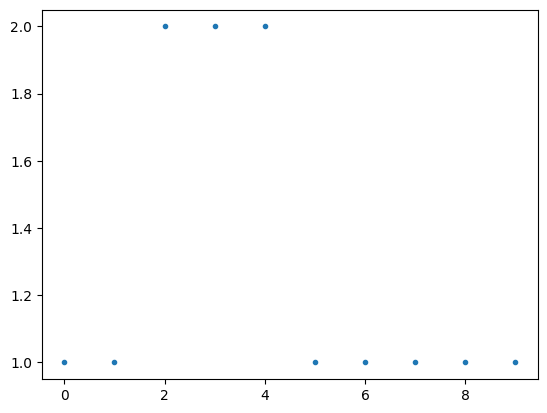

In [35]:
x = simul_markov(T2,10,1)
plt.plot(x,'.');

In [37]:
# bonus : on peut regarder la convergence des pi(n) vers la loi stationnaire:

# vecteur ligne pi(1) = (P(X1=1),P(X1=2)) = (1,0)
pi1 = np.array([[1,0]])
pi2 = pi1 @ T2
print(pi2)

[[0.7 0.3]]


In [38]:
pi3 = pi2 @ T2
print(pi3)

[[0.55 0.45]]


In [39]:
# on calcule pi(n) pour n=100. Du fait de la convergence très rapide vers
# la loi stationnaire, ce vecteur est en fait numériquement égal à la loi limite:
pi_101 = pi1 @ np.linalg.matrix_power(T2,99)
print(pi_101)

[[0.4 0.6]]
